This code is authored by Raghav
It performs a percolation analysis on the network

# Import the libraries

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from networkx.algorithms import bipartite
import pandas as pd
import random

# Making the required bipartite on networkx

In [2]:
def add_viz_shapes(B,
                   shapes={0: "square", 1: "triangle"},    # GEXF viz shape (ignored by stock Gephi)
                   polygon_sides={0: 4, 1: 3},             # used by the Polygon plugin
                   colors={0: (41, 125, 195), 1: (204, 204, 204)},
                   sizes={0: 10.0, 1: 10.0}):
    # GExf generator
    for n, d in B.nodes(data=True):
        p = d["bipartite"]
        r, g, b = colors[p]
        d["Polygon"] = int(polygon_sides[p])               # Gephi Polygon plugin: number of sides
        d["viz"] = {"shape": shapes[p],
                    "color": {"r": r, "g": g, "b": b, "a": 1.0},
                    "size": float(sizes[p])}
    return B


In [3]:
nodes = pd.read_csv("nodes_8.0.csv")
edges = pd.read_csv("edges_5.0.csv")

B = nx.Graph()
for r in nodes.itertuples():
    B.add_node(r.Id, bipartite=0 if r.Type == "Recipe" else 1,
               label=r.Label, cuisine=r.Cuisine, type=r.Type)
B.add_edges_from(edges[["Source", "Target"]].itertuples(index=False, name=None))
 
recipes = {n for n, d in B.nodes(data=True) if d["bipartite"] == 0}
ingredients = set(B) - recipes
assert nx.is_bipartite(B)

B = add_viz_shapes(B)
nx.write_gexf(B, "recipes_ingredients.gexf")


# Making the one mode projections from the given data

In [24]:
def basic_stats(G, name="", clustering=False):
    '''Basic structural parameters of a one-mode graph.'''
    n, m = G.number_of_nodes(), G.number_of_edges()
    deg = np.array([d for _, d in G.degree()])
    comps = sorted((len(c) for c in nx.connected_components(G)), reverse=True)
    s = {
        "nodes": n,
        "edges": m,
        "density": nx.density(G),
        "avg_degree": deg.mean(),
        "median_degree": np.median(deg),
        "max_degree": deg.max(),
        "min_degree": deg.min(),
        "isolated_nodes": nx.number_of_isolates(G),
        "components": len(comps),
        "giant_component_size": comps[0],
        "giant_component_frac": comps[0] / n,
        "MR" : molloy_reed(G)
    }
    if nx.is_weighted(G):
        w = np.array([d["weight"] for _, _, d in G.edges(data=True)])
        s.update({"avg_edge_weight": w.mean(), "max_edge_weight": w.max(),
                  "avg_strength": 2 * w.sum() / n})
    if clustering:                          # slower on dense graphs
        s["transitivity"] = nx.transitivity(G)
        s["avg_clustering"] = nx.average_clustering(G)
    return pd.Series(s, name=name)


MAX_FRAC = 0.001  # drop ingredients used in more than MAX_FRAC of recipes before projecting recipes
common = {i for i in ingredients if int(B.degree(i)) > MAX_FRAC * len(recipes)}
print(f"Dropping {len(common)} trivial ingredients, e.g.", sorted(common, key=B.degree, reverse=True)[:8])
B_filter = B.copy()
B_filter.remove_nodes_from(common)

R = bipartite.weighted_projected_graph(B_filter, recipes)   # recipe-recipe
I = bipartite.weighted_projected_graph(B, ingredients)      # ingredient-ingredient

bip = pd.Series({
    "recipes": len(recipes),
    "ingredients": len(ingredients),
    "edges": B.number_of_edges(),
    "bipartite_density": bipartite.density(B, recipes),
    "avg_ingredients_per_recipe": np.mean([B.degree(r) for r in recipes]),
    "avg_recipes_per_ingredient": np.mean([B.degree(i) for i in ingredients]),
}, name="Bipartite")

table = pd.concat([basic_stats(I, "Ingredient projection", clustering=True),
                   basic_stats(R, "Recipe projection", clustering=True)], axis=1)
print(bip.round(4).to_string())
print(table.round(4).to_string())
table.to_csv("projection_basic_stats.csv")

R_G = add_viz_shapes(R)
I_G = add_viz_shapes(I)
nx.write_gexf(R_G, "recipes_one_mode.gexf")
nx.write_gexf(I_G, "ingredients_one_mode.gexf")

Dropping 458 trivial ingredients, e.g. ['salt', 'turmeric powder', 'sunflower oil', 'green chillies', 'onion', 'red chilli powder', 'cumin seeds', 'coriander leaves']
recipes                        3933.0000
ingredients                    1034.0000
edges                         47353.0000
bipartite_density                 0.0116
avg_ingredients_per_recipe       12.0399
avg_recipes_per_ingredient       45.7959
                      Ingredient projection  Recipe projection
nodes                             1034.0000          3933.0000
edges                            31472.0000           353.0000
density                              0.0589             0.0000
avg_degree                          60.8743             0.1795
median_degree                       25.0000             0.0000
max_degree                         895.0000             5.0000
min_degree                           3.0000             0.0000
isolated_nodes                       0.0000          3498.0000
components          

### Note
* Shows very high clustering

# Basic Robustness experiments on both the one modes

## The functions for the experiment

In [23]:
def kappa(net):
    '''Molloy-Reed Parameter'''
    deg = np.array([d[1] for d in net.degree()])
    return np.mean(deg**2) / np.mean(deg)

def P_inf(net, N0):
    '''Fraction occupied by Giant component'''
    if net.number_of_nodes() == 0: #empty case
        return 0.0, 0.0
    sizes = sorted((len(c) for c in nx.connected_components(net)), reverse=True)
    s2 = sizes[1] if len(sizes) > 1 else 0
    return sizes[0] / N0, s2 / N0                   # (P_inf, second-largest fraction)

def simulate_failure(G, mode="random", step=0.02, seed=None):
    '''Failure simulation'''
    rng = random.Random(seed)
    net = G.copy()
    N0 = net.number_of_nodes()
    order = None
    if mode == "random":
        order = list(net.nodes()); rng.shuffle(order)   # shuffle once, not per removal
    fs = np.arange(0, 1 + 1e-9, step)
    P, S2, removed = [], [], 0
    for f in fs:
        target = int(round(f * N0))
        while removed < target:
            if mode == "random":
                node = order[removed]
            elif mode == "attack":
                node = max(net.degree(), key=lambda x: x[1])[0]
            else:
                raise ValueError("mode must be 'random' or 'attack'")
            net.remove_node(node); removed += 1
        p, s2 = P_inf(net, N0)
        P.append(p); S2.append(s2)
    return fs, np.array(P), np.array(S2)

def average_random(G, runs=10, step=0.02):
    '''Calls the main simulate failure for sampling'''
    res = [simulate_failure(G, "random", step, seed=s) for s in range(runs)]
    fs = res[0][0]
    return fs, np.mean([r[1] for r in res], 0), np.mean([r[2] for r in res], 0)


def fc_theory_random(G):
    '''Theoretical f_c from Molloy-Reed'''
    return 1 - 1 / (kappa(G) - 1)

def fc_from_S2(fs, S2):
    '''Prediction of second peak'''
    return fs[int(np.argmax(S2))]
'''Convenience defines these'''
STEP = 0.02
RUNS = {"Ingredient projection": 20, "Recipe projection": 5}   
 
def robustness(G, runs):
    P_rand = np.mean([simulate_failure(G, "random", STEP, seed=s) for s in range(runs)], axis=0)
    P_att = np.array(simulate_failure(G, "attack", STEP))
    return P_rand, P_att
 
def fc_from_curve(P, step=STEP, level=0.05):
    '''Theoretical f_c finder'''
    P = np.asarray(P) / P[0]
    below = np.where(P < level)[0]
    return below[0] * step if len(below) else np.nan

def molloy_reed(G):
    if not G.number_of_nodes():
        return 0
    deg = np.array([d  for _,d in G.degree()])
    k_mean = np.mean(deg)
    k2_mean = np.mean(deg**2)
    kappa = k2_mean/k_mean
    return kappa


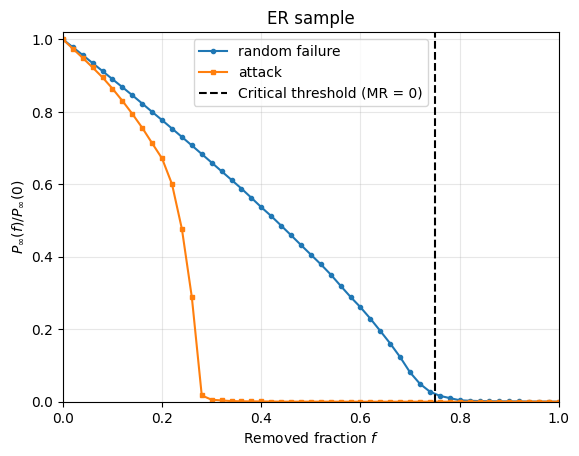

In [ ]:
# Testing the coherence of the function
name = "ER sample"
G = nx.gnm_random_graph(10**4, 2*10**4)

P_rand_I, P_att_I = robustness(G, 5)
f_I = np.asarray(P_rand_I)[0]                 # x-axis (removed fraction)
P_rand_I = np.asarray(P_rand_I)[1]            # P_inf, random failure
P_att_I = np.asarray(P_att_I)[1]              # P_inf, attack

df_I = pd.DataFrame([dict(
    N=G.number_of_nodes(), M=G.number_of_edges(),
    P0=float(P_rand_I[0]),
    fc_random=float(fc_from_curve(P_rand_I)),
    fc_attack=float(fc_from_curve(P_att_I)))], index=[name]).round(3)

plt.plot(f_I, P_rand_I / P_rand_I[0], marker="o", ms=3, label="random failure")
plt.plot(f_I, P_att_I / P_att_I[0], marker="s", ms=3, label="attack")
plt.axvline(
    x= 1 - 1/(molloy_reed(G)-1) ,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Critical threshold (kappa = 2)"
)
plt.xlabel(r"Removed fraction $f$"); plt.ylabel(r"$P_\infty(f)/P_\infty(0)$")
plt.title(name); plt.xlim(0, 1); plt.ylim(0, 1.02)
plt.legend(); plt.grid(alpha=0.3); plt.show()


## One mode of Ingredients

                          N      M   P0  fc_random  fc_attack
Ingredient projection  1034  31472  1.0       0.94       0.32


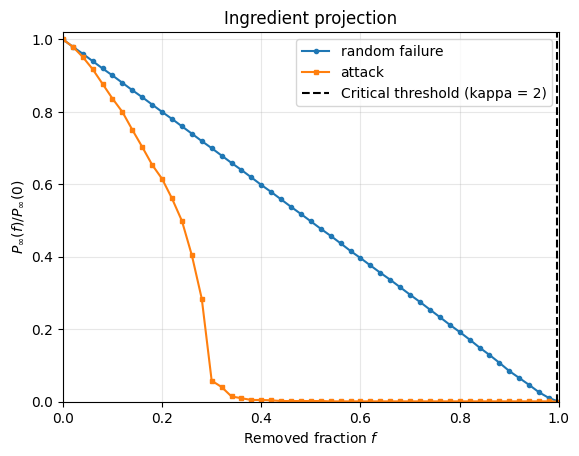

In [27]:
name = "Ingredient projection"
G = I

P_rand_I, P_att_I = robustness(G, RUNS[name])
f_I = np.asarray(P_rand_I)[0]                 # x-axis (removed fraction)
P_rand_I = np.asarray(P_rand_I)[1]            # P_inf, random failure
P_att_I = np.asarray(P_att_I)[1]              # P_inf, attack

df_I = pd.DataFrame([dict(
    N=G.number_of_nodes(), M=G.number_of_edges(),
    P0=float(P_rand_I[0]),
    fc_random=float(fc_from_curve(P_rand_I)),
    fc_attack=float(fc_from_curve(P_att_I)))], index=[name]).round(3)

print(df_I.to_string())
df_I.to_csv("percolation_ingredient.csv")

plt.plot(f_I, P_rand_I / P_rand_I[0], marker="o", ms=3, label="random failure")
plt.plot(f_I, P_att_I / P_att_I[0], marker="s", ms=3, label="attack")
plt.axvline(
    x= 1 - 1/(molloy_reed(G)-1) ,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Critical threshold (kappa = 2)"
)
plt.xlabel(r"Removed fraction $f$"); plt.ylabel(r"$P_\infty(f)/P_\infty(0)$")
plt.title(name); plt.xlim(0, 1); plt.ylim(0, 1.02)
plt.legend(); plt.grid(alpha=0.3); plt.show()

## One mode of Recipes

                      N    M     P0  fc_random  fc_attack
Recipe projection  3933  353  0.002        1.0        1.0
1.9263456090651558


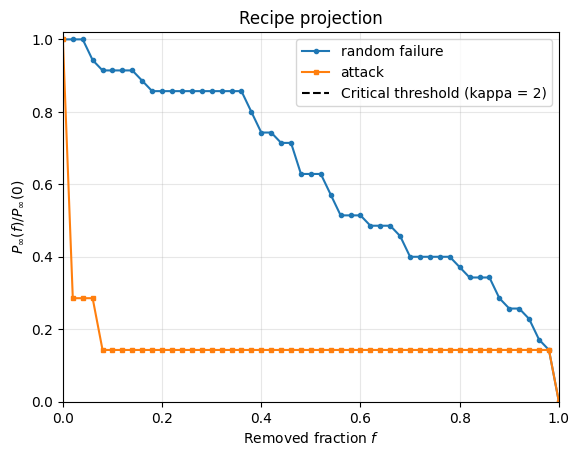

In [ ]:
name = "Recipe projection"
G = R

P_rand_R, P_att_R = robustness(G, runs=RUNS[name])
f_R = np.asarray(P_rand_R)[0]                 # x-axis (removed fraction)
P_rand_R = np.asarray(P_rand_R)[1]            # P_inf, random failure
P_att_R = np.asarray(P_att_R)[1]              # P_inf, attack

df_R = pd.DataFrame([dict(
    N=G.number_of_nodes(), M=G.number_of_edges(),
    P0=float(P_rand_R[0]),
    fc_random=float(fc_from_curve(P_rand_R)),
    fc_attack=float(fc_from_curve(P_att_R)))], index=[name]).round(3)

print(df_R.to_string())
df_R.to_csv("percolation_ingredient.csv")

plt.plot(f_R, P_rand_R / P_rand_R[0], marker="o", ms=3, label="random failure")
plt.plot(f_R, P_att_R / P_att_R[0], marker="s", ms=3, label="attack")
plt.axvline(
    x= 1 - 1/(molloy_reed(G)-1) ,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Critical threshold (kappa = 2)"
)
plt.xlabel(r"Removed fraction $f$"); plt.ylabel(r"$P_\infty(f)/P_\infty(0)$")
plt.title(name); plt.xlim(0, 1); plt.ylim(0, 1.02)
plt.legend(); plt.grid(alpha=0.3); plt.show()

# Cuisine Wise analysis

Total recipe IDs in CSV: 3933
Total nodes in B_filter: 4509
Andhra               N= 109 Nodes= 119 Edges=    11 Density=0.0016 R_attack=0.2180 R_random=0.5024
Skipping Assamese: only 28 recipe nodes found
Skipping Awadhi: only 33 recipe nodes found
Bengali Recipes      N= 150 Nodes= 173 Edges=    29 Density=0.0019 R_attack=0.2300 R_random=0.6368
Skipping Bihari: only 25 recipe nodes found
Chettinad            N=  65 Nodes=  72 Edges=     8 Density=0.0031 R_attack=0.2750 R_random=0.5587
Skipping Coorg: only 14 recipe nodes found
Goan Recipes         N=  85 Nodes=  93 Edges=     9 Density=0.0021 R_attack=0.3567 R_random=0.6763
Gujarati Recipes﻿    N=  96 Nodes= 104 Edges=    11 Density=0.0021 R_attack=0.3633 R_random=0.7077
Skipping Haryana: only 2 recipe nodes found
Skipping Himachal: only 15 recipe nodes found
Skipping Hyderabadi: only 26 recipe nodes found
Indian               N= 927 Nodes=1041 Edges=   179 Density=0.0003 R_attack=0.1700 R_random=0.5931
Skipping Jharkhand: only 2 reci

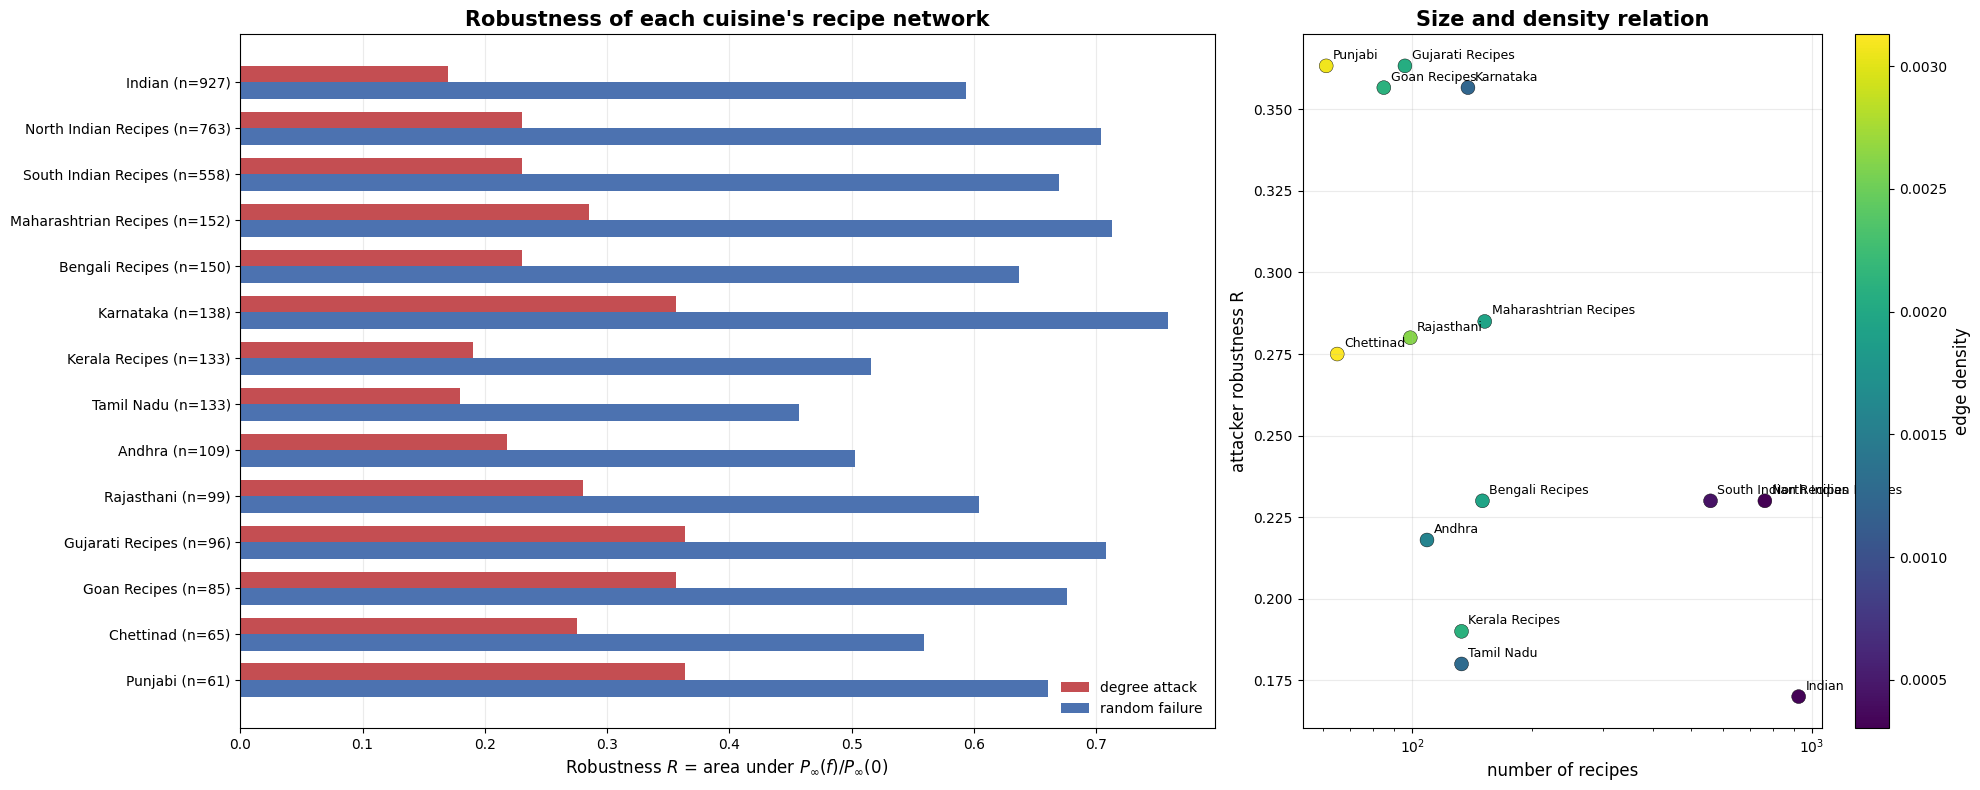

In [ ]:
# ------------------------------------------------------------
# 1. PARAMETERS
# ------------------------------------------------------------

STEP = 0.02
RUNS = 20
RANDOM_SEED = 42

COLLAPSE_LEVEL = 0.05


# ------------------------------------------------------------
# 2. SIMULATE NODE REMOVAL
# ------------------------------------------------------------

def simulate_failure(G, mode="random", step=STEP, seed=None):

    rng = random.Random(seed)

    net = G.copy()

    N0 = net.number_of_nodes()

    if N0 == 0:
        return np.array([0.0]), np.array([0.0])

    if mode == "random":
        order = list(net.nodes())
        rng.shuffle(order)

    elif mode != "attack":
        raise ValueError("mode must be 'random' or 'attack'")

    fs = np.arange(0, 1 + 1e-9, step)

    P = []
    removed = 0

    for f in fs:

        target = min(int(round(f * N0)), N0)

        while removed < target:

            if mode == "random":

                node = order[removed]

            elif mode == "attack":

                # Adaptive degree attack
                node = max(
                    net.degree(),
                    key=lambda x: x[1]
                )[0]

            net.remove_node(node)

            removed += 1

        if net.number_of_nodes() == 0:

            P.append(0.0)

        else:

            largest_component = max(
                nx.connected_components(net),
                key=len
            )

            P.append(len(largest_component) / N0)

    return fs, np.asarray(P)


# ------------------------------------------------------------
# 3. CALCULATE ROBUSTNESS
# ------------------------------------------------------------

def calculate_robustness(G, runs=RUNS):

    if G.number_of_nodes() == 0:

        return np.nan, np.nan, np.nan, np.nan

    # Random failure

    random_curves = []

    for run in range(runs):

        fs, P_random = simulate_failure(
            G,
            mode="random",
            seed=RANDOM_SEED + run
        )

        random_curves.append(P_random)

    P_random_avg = np.mean(
        random_curves,
        axis=0
    )

    # Adaptive degree attack

    fs, P_attack = simulate_failure(
        G,
        mode="attack",
        seed=RANDOM_SEED
    )

    # Normalize

    P_random_norm = (
        P_random_avg / P_random_avg[0]
        if P_random_avg[0] > 0
        else P_random_avg
    )

    P_attack_norm = (
        P_attack / P_attack[0]
        if P_attack[0] > 0
        else P_attack
    )

    # Robustness = area under normalized curve

    R_random = np.trapz(
        P_random_norm,
        fs
    )

    R_attack = np.trapz(
        P_attack_norm,
        fs
    )

    return (
        R_attack,
        R_random,
        P_attack_norm,
        P_random_norm
    )


# ------------------------------------------------------------
# 4. CONSTRUCT CUISINE-SPECIFIC RECIPE NETWORKS
# ------------------------------------------------------------

cuisine_results = []

cuisine_graphs = {}

# Get cuisine names from CSV
remove_list = []
cuisine_values = sorted(
    set(
        nodes.loc[
            nodes["Type"] == "Recipe",
            "Cuisine"
        ].dropna().unique()
    ) - set(remove_list)
)
# Ensure recipe IDs are strings
nodes["Id"] = nodes["Id"].astype(str)

# Get recipe nodes from the bipartite graph
B_filter_nodes = set(B_filter.nodes())

print("Total recipe IDs in CSV:",
      nodes.loc[nodes["Type"] == "Recipe", "Id"].nunique())

print("Total nodes in B_filter:",
      B_filter.number_of_nodes())


for cuisine in cuisine_values:

    # --------------------------------------------------------
    # Select cuisine-specific recipe IDs directly from CSV
    # --------------------------------------------------------

    cuisine_recipes_csv = set(
        nodes.loc[
            (nodes["Type"] == "Recipe") &
            (nodes["Cuisine"] == cuisine),
            "Id"
        ]
    )

    # --------------------------------------------------------
    # Retain only recipes present in B_filter
    # --------------------------------------------------------

    cuisine_recipes = (
        cuisine_recipes_csv & B_filter_nodes
    )

    N_recipes = len(cuisine_recipes)

    if N_recipes < 50:

        print(
            f"Skipping {cuisine}: "
            f"only {N_recipes} recipe nodes found"
        )

        continue

    # --------------------------------------------------------
    # Project cuisine-specific recipes into recipe-recipe
    # network using shared ingredients
    # --------------------------------------------------------

    G_cuisine = bipartite.weighted_projected_graph(
        B_filter,
        cuisine_recipes
    )

    # Remove self-loops

    G_cuisine.remove_edges_from(
        nx.selfloop_edges(G_cuisine)
    )

    # --------------------------------------------------------
    # Network metrics
    # --------------------------------------------------------

    density = nx.density(G_cuisine)

    N_nodes = G_cuisine.number_of_nodes()

    N_edges = G_cuisine.number_of_edges()

    # --------------------------------------------------------
    # Calculate robustness
    # --------------------------------------------------------

    R_attack, R_random, P_attack, P_random = (
        calculate_robustness(
            G_cuisine,
            runs=RUNS
        )
    )

    # Store graph

    cuisine_graphs[cuisine] = G_cuisine

    # Store results

    cuisine_results.append({

        "Cuisine": cuisine,

        "N_recipes": N_recipes,

        "N_nodes": N_nodes,

        "N_edges": N_edges,

        "Density": density,

        "R_attack": R_attack,

        "R_random": R_random,

    })

    print(
        f"{cuisine:20s} "
        f"N={N_recipes:4d} "
        f"Nodes={N_nodes:4d} "
        f"Edges={N_edges:6d} "
        f"Density={density:.4f} "
        f"R_attack={R_attack:.4f} "
        f"R_random={R_random:.4f}"
    )


# ------------------------------------------------------------
# 5. CREATE RESULTS DATAFRAME
# ------------------------------------------------------------

df_cuisine = pd.DataFrame(
    cuisine_results
)

df_cuisine = df_cuisine.sort_values(
    "N_recipes",
    ascending=False
).reset_index(drop=True)

print("\nCuisine robustness results:")

print(
    df_cuisine.round(4).to_string(index=False)
)

df_cuisine.to_csv(
    "cuisine_robustness_results.csv",
    index=False
)


# ------------------------------------------------------------
# 6. PLOT LEFT PANEL
# ROBUSTNESS OF EACH CUISINE
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(20, 8),
    gridspec_kw={"width_ratios": [1.5, 1]}
)

ax1 = axes[0]

y = np.arange(
    len(df_cuisine)
)

bar_height = 0.36

ax1.barh(
    y - bar_height / 2,
    df_cuisine["R_attack"],
    height=bar_height,
    color="#C44E52",
    label="degree attack"
)

ax1.barh(
    y + bar_height / 2,
    df_cuisine["R_random"],
    height=bar_height,
    color="#4C72B0",
    label="random failure"
)

labels = [
    f"{row.Cuisine} (n={row.N_recipes})"
    for row in df_cuisine.itertuples()
]

ax1.set_yticks(y)

ax1.set_yticklabels(labels)

ax1.invert_yaxis()

ax1.set_xlabel(
    r"Robustness $R$ = area under "
    r"$P_\infty(f)/P_\infty(0)$ ",
    fontsize=12
)

ax1.set_title(
    "Robustness of each cuisine's recipe network",
    fontsize=15,
    fontweight="bold"
)

ax1.legend(
    loc="lower right",
    frameon=False
)

ax1.grid(
    axis="x",
    alpha=0.25
)

ax1.set_axisbelow(True)


# ------------------------------------------------------------
# 7. PLOT RIGHT PANEL
# SIZE AND DENSITY DRIVE ROBUSTNESS
# ------------------------------------------------------------

ax2 = axes[1]

scatter = ax2.scatter(

    df_cuisine["N_recipes"],

    df_cuisine["R_attack"],

    c=df_cuisine["Density"],

    cmap="viridis",

    s=100,

    edgecolors="black",

    linewidths=0.3

)

# Label cuisine points

for row in df_cuisine.itertuples():

    ax2.annotate(

        row.Cuisine,

        (
            row.N_recipes,
            row.R_attack
        ),

        xytext=(5, 5),

        textcoords="offset points",

        fontsize=9

    )

ax2.set_xscale("log")

ax2.set_xlabel(
    "number of recipes",
    fontsize=12
)

ax2.set_ylabel(
    "attacker robustness R",
    fontsize=12
)

ax2.set_title(
    "Size and density relation",
    fontsize=15,
    fontweight="bold"
)

ax2.grid(
    alpha=0.25
)

cbar = plt.colorbar(
    scatter,
    ax=ax2
)

cbar.set_label(
    "edge density",
    fontsize=12
)


# ------------------------------------------------------------
# 8. SAVE FIGURE
# ------------------------------------------------------------

plt.tight_layout()

plt.savefig(
    "fig8_cuisine_robustness.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Andhra               Recipes= 109 Ingredients=  12 R_attack=0.9500 R_random=0.9480
Bengali Recipes      Recipes= 150 Ingredients=  32 R_attack=0.8831 R_random=0.9029
Chettinad            Recipes=  65 Ingredients=  15 R_attack=0.9135 R_random=0.9126
Goan Recipes         Recipes=  85 Ingredients=  20 R_attack=0.8815 R_random=0.8845
Gujarati Recipes﻿    Recipes=  96 Ingredients=  12 R_attack=0.9185 R_random=0.9275
Indian               Recipes= 927 Ingredients= 245 R_attack=0.8607 R_random=0.8747
Karnataka            Recipes= 138 Ingredients=  17 R_attack=0.9400 R_random=0.9408
Kerala Recipes       Recipes= 133 Ingredients=  22 R_attack=0.9133 R_random=0.9180
Maharashtrian Recipes Recipes= 152 Ingredients=  34 R_attack=0.8848 R_random=0.8934
North Indian Recipes Recipes= 763 Ingredients= 139 R_attack=0.9053 R_random=0.9120
Punjabi              Recipes=  61 Ingredients=  12 R_attack=0.9038 R_random=0.9063
Rajasthani           Recipes=  99 Ingredients=  14 R_attack=0.9106 R_random=0.9203
Sou

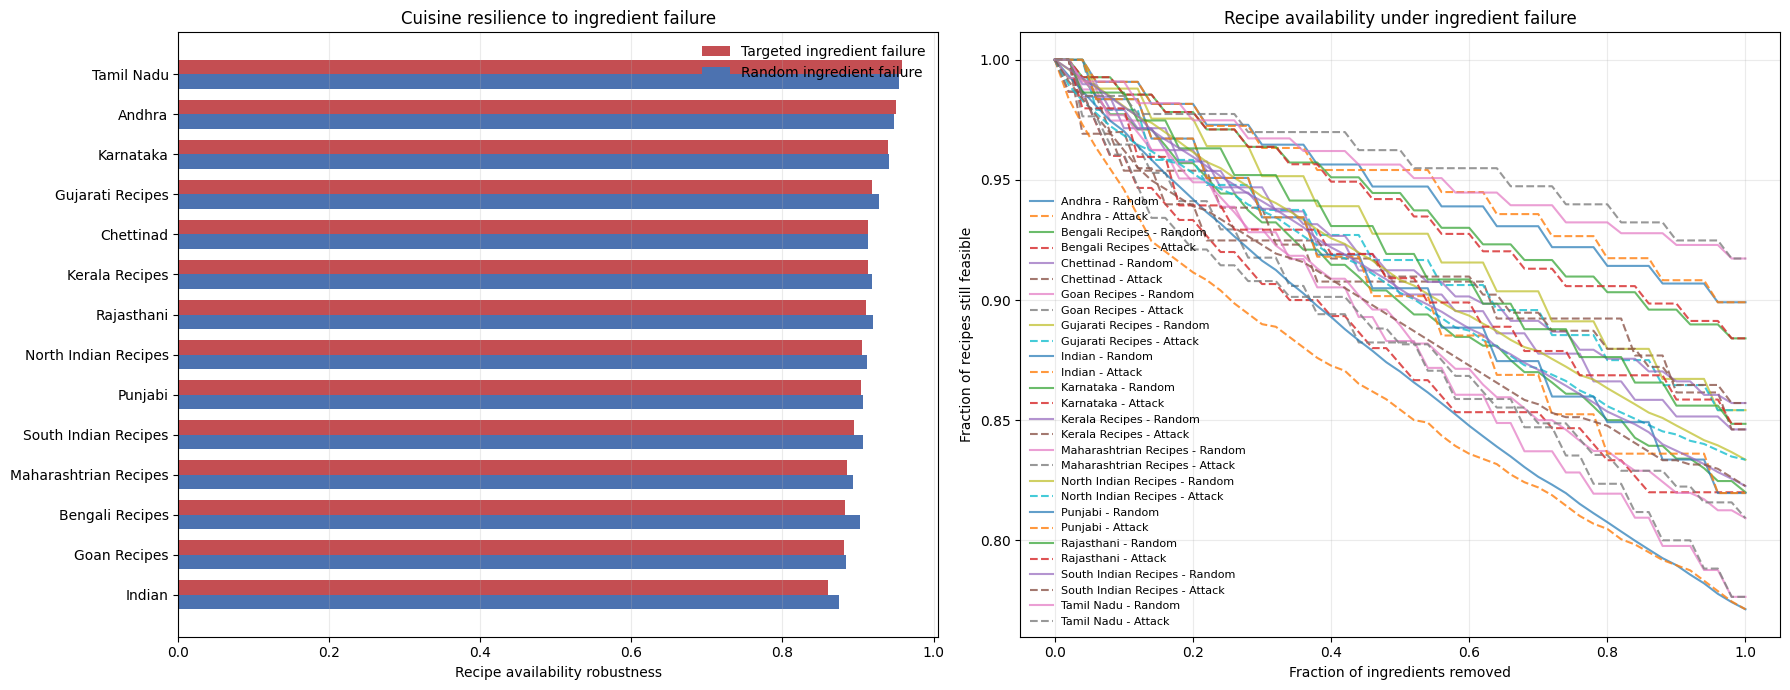

In [36]:
# ============================================================
# 1. PARAMETERS
# ============================================================

STEP = 0.02
RUNS = 20
RANDOM_SEED = 42

remove_list = [
    # "Andhra",
    # "Bengali"
]


# ============================================================
# 2. SIMULATE INGREDIENT FAILURE
# ============================================================

def simulate_ingredient_failure(
    G,
    recipes,
    mode="random",
    step=STEP,
    seed=None
):

    rng = random.Random(seed)

    failed_ingredients = set()

    N0 = len(recipes)

    if N0 == 0:
        return np.array([0.0]), np.array([0.0])

    # Get ingredients connected to each recipe
    recipe_ingredients = {
        r: set(G.neighbors(r))
        for r in recipes
    }

    all_ingredients = set()

    for ingredients in recipe_ingredients.values():
        all_ingredients.update(ingredients)

    N_ingredients = len(all_ingredients)

    if N_ingredients == 0:
        return np.array([0.0]), np.array([1.0])

    # Ingredient removal order
    if mode == "random":

        order = list(all_ingredients)
        rng.shuffle(order)

    elif mode == "attack":

        # Rank ingredients by number of recipes using them
        order = sorted(
            all_ingredients,
            key=lambda ingredient: sum(
                ingredient in ingredients
                for ingredients in recipe_ingredients.values()
            ),
            reverse=True
        )

    else:

        raise ValueError(
            "mode must be 'random' or 'attack'"
        )

    fs = np.arange(0, 1 + 1e-9, step)

    P = []

    removed = 0

    for f in fs:

        target = min(
            int(round(f * N_ingredients)),
            N_ingredients
        )

        while removed < target:

            failed_ingredients.add(order[removed])

            removed += 1

        # A recipe is feasible only if all its ingredients
        # remain available.

        available_recipes = sum(
            1
            for ingredients in recipe_ingredients.values()
            if ingredients.isdisjoint(failed_ingredients)
        )

        P.append(
            available_recipes / N0
        )

    return fs, np.asarray(P)


# ============================================================
# 3. CALCULATE RECIPE AVAILABILITY ROBUSTNESS
# ============================================================

def calculate_ingredient_robustness(
    G,
    recipes,
    runs=RUNS
):

    random_curves = []

    for run in range(runs):

        fs, P_random = simulate_ingredient_failure(
            G,
            recipes,
            mode="random",
            seed=RANDOM_SEED + run
        )

        random_curves.append(P_random)

    P_random_avg = np.mean(
        random_curves,
        axis=0
    )

    fs, P_attack = simulate_ingredient_failure(
        G,
        recipes,
        mode="attack",
        seed=RANDOM_SEED
    )

    # Area under normalized recipe availability curve
    R_random = np.trapz(
        P_random_avg,
        fs
    )

    R_attack = np.trapz(
        P_attack,
        fs
    )

    return (
        R_attack,
        R_random,
        P_attack,
        P_random_avg
    )


# ============================================================
# 4. CUISINE-SPECIFIC ANALYSIS
# ============================================================

ingredient_failure_results = []

ingredient_failure_curves = {}

recipe_data = nodes.loc[
    nodes["Type"] == "Recipe"
].copy()

recipe_data["Id"] = recipe_data["Id"].astype(str)

B_filter_nodes = set(B_filter.nodes())

cuisine_values = sorted(
    set(recipe_data["Cuisine"].dropna().unique())
    - set(remove_list)
)

for cuisine in cuisine_values:

    # Select recipes
    cuisine_recipes = set(
        recipe_data.loc[
            recipe_data["Cuisine"] == cuisine,
            "Id"
        ]
    ) & B_filter_nodes

    if len(cuisine_recipes) < 50:
        continue

    # Count distinct ingredients
    cuisine_ingredients = set()

    for recipe in cuisine_recipes:

        cuisine_ingredients.update(
            B_filter.neighbors(recipe)
        )

    N_recipes = len(cuisine_recipes)

    N_ingredients = len(cuisine_ingredients)

    # Calculate ingredient failure robustness
    R_attack, R_random, P_attack, P_random = (
        calculate_ingredient_robustness(
            B_filter,
            cuisine_recipes,
            runs=RUNS
        )
    )

    ingredient_failure_curves[cuisine] = {
        "fs": np.arange(0, 1 + 1e-9, STEP),
        "P_attack": P_attack,
        "P_random": P_random
    }

    ingredient_failure_results.append({

        "Cuisine": cuisine,

        "N_recipes": N_recipes,

        "N_ingredients": N_ingredients,

        "R_attack": R_attack,

        "R_random": R_random,

        "Recipes_remaining_random_50pct": (
            P_random[min(round(0.5 / STEP), len(P_random)-1)]
            * N_recipes
        ),

        "Recipes_remaining_attack_50pct": (
            P_attack[min(round(0.5 / STEP), len(P_attack)-1)]
            * N_recipes
        )

    })

    print(
        f"{cuisine:20s} "
        f"Recipes={N_recipes:4d} "
        f"Ingredients={N_ingredients:4d} "
        f"R_attack={R_attack:.4f} "
        f"R_random={R_random:.4f}"
    )


# ============================================================
# 5. RESULTS DATAFRAME
# ============================================================

df_ingredient_failure = pd.DataFrame(
    ingredient_failure_results
)

df_ingredient_failure = df_ingredient_failure.sort_values(
    "R_attack",
    ascending=False
).reset_index(drop=True)

print("\nIngredient failure results:")

print(
    df_ingredient_failure.round(4).to_string(index=False)
)

df_ingredient_failure.to_csv(
    "cuisine_ingredient_failure_results.csv",
    index=False
)


# ============================================================
# 6. PLOT RECIPE AVAILABILITY
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(18, 7)
)

# ------------------------------------------------------------
# LEFT: Compare cuisine robustness
# ------------------------------------------------------------

ax1 = axes[0]

y = np.arange(
    len(df_ingredient_failure)
)

height = 0.36

ax1.barh(
    y - height/2,
    df_ingredient_failure["R_attack"],
    height=height,
    label="Targeted ingredient failure",
    color="#C44E52"
)

ax1.barh(
    y + height/2,
    df_ingredient_failure["R_random"],
    height=height,
    label="Random ingredient failure",
    color="#4C72B0"
)

ax1.set_yticks(y)

ax1.set_yticklabels(
    df_ingredient_failure["Cuisine"]
)

ax1.invert_yaxis()

ax1.set_xlabel(
    "Recipe availability robustness"
)

ax1.set_title(
    "Cuisine resilience to ingredient failure"
)

ax1.legend(frameon=False)

ax1.grid(
    axis="x",
    alpha=0.25
)


# ------------------------------------------------------------
# RIGHT: Recipe availability curves
# ------------------------------------------------------------

ax2 = axes[1]

for cuisine, data in ingredient_failure_curves.items():

    ax2.plot(
        data["fs"],
        data["P_random"],
        label=f"{cuisine} - Random",
        alpha=0.7
    )

    ax2.plot(
        data["fs"],
        data["P_attack"],
        linestyle="--",
        alpha=0.8,
        label=f"{cuisine} - Attack"
    )

ax2.set_xlabel(
    "Fraction of ingredients removed"
)

ax2.set_ylabel(
    "Fraction of recipes still feasible"
)

ax2.set_title(
    "Recipe availability under ingredient failure"
)

ax2.grid(alpha=0.25)

ax2.legend(
    fontsize=8,
    frameon=False
)

plt.tight_layout()

plt.savefig(
    "ingredient_failure_recipe_availability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()